### Convergence

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [453]:
colors = ["#A12864", "#98DA4C"]
labels = ["wo", "wz"]

In [ ]:
# r = run.scan_history(min_step=0, max_step=100_000) # nvr pass keys
# r = pd.DataFrame(r)
# r

In [2]:
# Load run instead
run_id = "b9opf3p7"

r = pd.read_pickle(f"{run_id}-log.pkl")
print(r.shape)

(1896470, 79)


In [7]:
def running_mean(x: pd.Series, n=100):
    return x.rolling(window=n, min_periods=1).mean()

def crop(df: pd.DataFrame, c: float):
    return df[df["episode"] <= c]

In [168]:
# save e_reward1.values to a file
np.save(f"o/e_reward-wo.npy", e_reward.values)
np.save(f"o/e_reward-wz.npy", e_reward1.values)
np.save(f"o/e_episode-r.npy", e_episode.values)

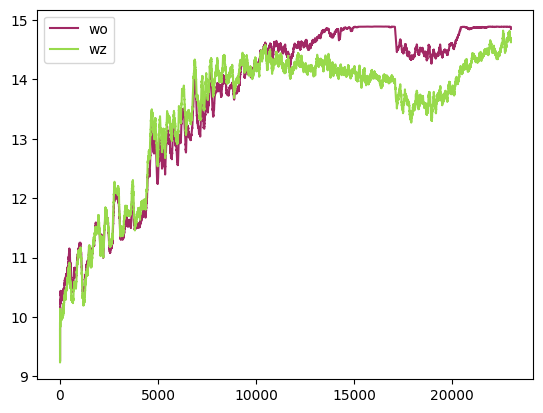

In [448]:
e_episode = np.load(f"o/e_episode-r.npy")
e_reward = np.load(f"o/e_reward-wo.npy")
e_reward1 = np.load(f"o/e_reward-wz.npy")

plt.plot(e_episode, e_reward, color=colors[0], label=labels[0], linestyle='-')
plt.plot(e_episode, e_reward1, color=colors[1], label=labels[1], linestyle='-')
plt.legend()
plt.show()

#### latency

In [447]:
np.save(f"o/e_latency-wo.npy", e_latency.values)
np.save(f"o/e_latency-wz.npy", e_latency1.values)
np.save(f"o/e_episode-latency.npy", e_episode.values)

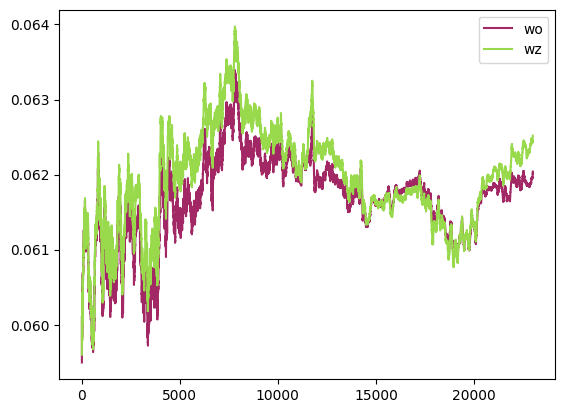

In [449]:
e_episode = np.load(f"o/e_episode-latency.npy")
e_latency = np.load(f"o/e_latency-wo.npy")
e_latency1 = np.load(f"o/e_latency-wz.npy")

plt.plot(e_episode, e_latency, color=colors[0], label=labels[0], linestyle='-')
plt.plot(e_episode, e_latency1, color=colors[1], label=labels[1], linestyle='-')
plt.legend()
plt.show()

#### lb


In [163]:
np.save(f"o/e_lb-wo.npy", e_lb.values)
np.save(f"o/e_lb-wz.npy", e_lb1.values)
np.save(f"o/e_episode-lb.npy", e_episode.values)

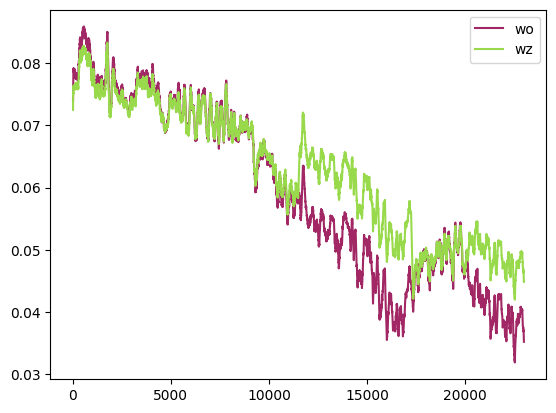

In [450]:
e_episode = np.load(f"o/e_episode-lb.npy")
e_lb = np.load(f"o/e_lb-wo.npy")
e_lb1 = np.load(f"o/e_lb-wz.npy")

plt.plot(e_episode, e_lb, color=colors[0], label=labels[0], linestyle='-')
plt.plot(e_episode, e_lb1, color=colors[1], label=labels[1], linestyle='-')
plt.legend()
plt.show()

#### RU

In [417]:
np.save(f"o/e_ru-wo.npy", e_ru.values)
np.save(f"o/e_ru-wz.npy", e_ru1.values)
np.save(f"o/e_episode-ru.npy", e_episode.values)

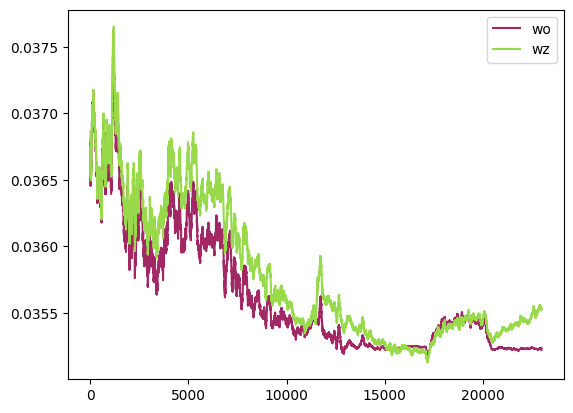

In [452]:
e_episode = np.load(f"o/e_episode-ru.npy")
e_ru = np.load(f"o/e_ru-wo.npy")
e_ru1 = np.load(f"o/e_ru-wz.npy")

plt.plot(e_episode, e_ru, color=colors[0], label=labels[0], linestyle='-')
plt.plot(e_episode, e_ru1, color=colors[1], label=labels[1], linestyle='-')
plt.legend()
plt.show()

# etc...

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import json
import os
def load_summary_files(directory, run_name):
    summaries = []
    for filename in os.listdir(directory):
        if filename.startswith(f"{run_name}-summary-") and filename.endswith(".json"):
            with open(os.path.join(directory, filename), 'r') as f:
                summaries.append(json.load(f))
    return summaries
def extract_metrics(summaries):
    metrics = []
    slas = []
    arrival_rates = []
    for summary in summaries:
        num_reqs = summary["num_reqs"]
        if num_reqs % 5 == 0:
            m_l = summary["latency"][0]
            m_lb = summary["lb"][0]
            m_ru = summary["ru"][0]
            s_l = summary["latency"][1]
            s_lb = summary["lb"][1]
            s_ru = summary["ru"][1]
            metrics.append((m_l, m_lb, m_ru, s_l, s_lb, s_ru))
            slas.append(summary["sla_violation"]/summary["ep_step"])
            arrival_rates.append(num_reqs)
    
    # use the index of arrival_rates to sort metrics and slas
    sorted_indices = np.argsort(arrival_rates)
    metrics = [metrics[i] for i in sorted_indices]
    slas = [slas[i] for i in sorted_indices]
    arrival_rates = [arrival_rates[i] for i in sorted_indices]
    return metrics, slas, arrival_rates

def extract_metrics_nms(summaries):
    metrics = []
    slas = []
    nmss = []
    for summary in summaries:
        nms = summary["nms"]
        if nms % 5 == 0:
            m_l = summary["latency"][0]
            m_lb = summary["lb"][0]
            m_ru = summary["ru"][0]
            s_l = summary["latency"][1]
            s_lb = summary["lb"][1]
            s_ru = summary["ru"][1]
            metrics.append((m_l, m_lb, m_ru, s_l, s_lb, s_ru))
            slas.append(summary["sla_violation"]/summary["ep_step"])
            nmss.append(nms)
    
    # use the index of arrival_rates to sort metrics and slas
    sorted_indices = np.argsort(nmss)
    metrics = [metrics[i] for i in sorted_indices]
    slas = [slas[i] for i in sorted_indices]
    nmss = [nmss[i] for i in sorted_indices]
    return metrics, slas, nmss


In [56]:
def plot_metrics(arrival_rates, metrics, slas):
    m_l, m_lb, m_ru, _,_,_ = zip(*metrics[0])
    m_l1, m_lb1, m_ru1, _,_,_ = zip(*metrics[1])

    arrival_rates1 = arrival_rates[1]
    arrival_rates = arrival_rates[0]

    slas1 = slas[1]
    slas = slas[0]

    np.save("o/arrival.npy", {
        "arrival_rates": arrival_rates,
        "latency_wz_toporag": m_l,
        "latency_wo_toporag": m_l1,
        "lb_wz_toporag": m_lb,
        "lb_wo_toporag": m_lb1,
        "ru_wz_toporag": m_ru,
        "ru_wo_toporag": m_ru1,
        "slas_wz_toporag": slas,
        "slas_wo_toporag": slas1
        }, allow_pickle=True)

    
    plt.figure(figsize=(12, 8))
    
    # Mean Latency
    plt.subplot(3, 2, 1)
    plt.plot(arrival_rates, m_l, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, m_l1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Mean Latency')
    plt.grid()
    plt.legend()
    
    # Mean Load Balancing
    plt.subplot(3, 2, 2)
    plt.plot(arrival_rates, m_lb, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, m_lb1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Mean Load Balancing')
    plt.grid()
    plt.legend()
    
    # Mean Resource Utilization
    plt.subplot(3, 2, 3)
    plt.plot(arrival_rates, m_ru, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, m_ru1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Mean Resource Utilization')
    plt.grid()
    plt.legend()


    # sla violations
    plt.subplot(3, 2, 4)
    plt.plot(arrival_rates, slas, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, slas1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Total SLA Violations')
    plt.grid()
    plt.legend()

    # Show plots
    plt.tight_layout()
    plt.show()

In [55]:
def plot_metrics_bar(arrival_rates, metrics, slas):
    m_l, m_lb, m_ru, _,_,_ = zip(*metrics[0])
    m_l1, m_lb1, m_ru1, _,_,_ = zip(*metrics[1])

    arrival_rates1 = arrival_rates[1]
    arrival_rates = arrival_rates[0]

    slas1 = slas[1]
    slas = slas[0]

    # Ensure arrival_rates and other x-axes are numpy arrays
    arrival_rates = np.array(arrival_rates)
    arrival_rates1 = np.array(arrival_rates1)

    np.save("o/nms.npy", {
        "n_ms": arrival_rates,
        "latency_wz_toporag": m_l,
        "latency_wo_toporag": m_l1,
        "lb_wz_toporag": m_lb,
        "lb_wo_toporag": m_lb1,
        "ru_wz_toporag": m_ru,
        "ru_wo_toporag": m_ru1,
        "slas_wz_toporag": slas,
        "slas_wo_toporag": slas1
    }, allow_pickle=True)

    bar_width = 0.35
    x = np.arange(len(arrival_rates))  # For positioning bars

    plt.figure(figsize=(12, 8))

    # Mean Latency
    plt.subplot(3, 2, 1)
    plt.bar(x - bar_width/2, m_l, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, m_l1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Mean Latency')
    plt.grid(True, axis='y')
    plt.legend()

    # Mean Load Balancing
    plt.subplot(3, 2, 2)
    plt.bar(x - bar_width/2, m_lb, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, m_lb1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Mean Load Balancing')
    plt.grid(True, axis='y')
    plt.legend()

    # Mean Resource Utilization
    plt.subplot(3, 2, 3)
    plt.bar(x - bar_width/2, m_ru, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, m_ru1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Mean Resource Utilization')
    plt.grid(True, axis='y')
    plt.legend()

    # SLA Violations
    plt.subplot(3, 2, 4)
    plt.bar(x - bar_width/2, slas, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, slas1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Total SLA Violations')
    plt.grid(True, axis='y')
    plt.legend()

    # Show plots
    plt.tight_layout()
    plt.show()


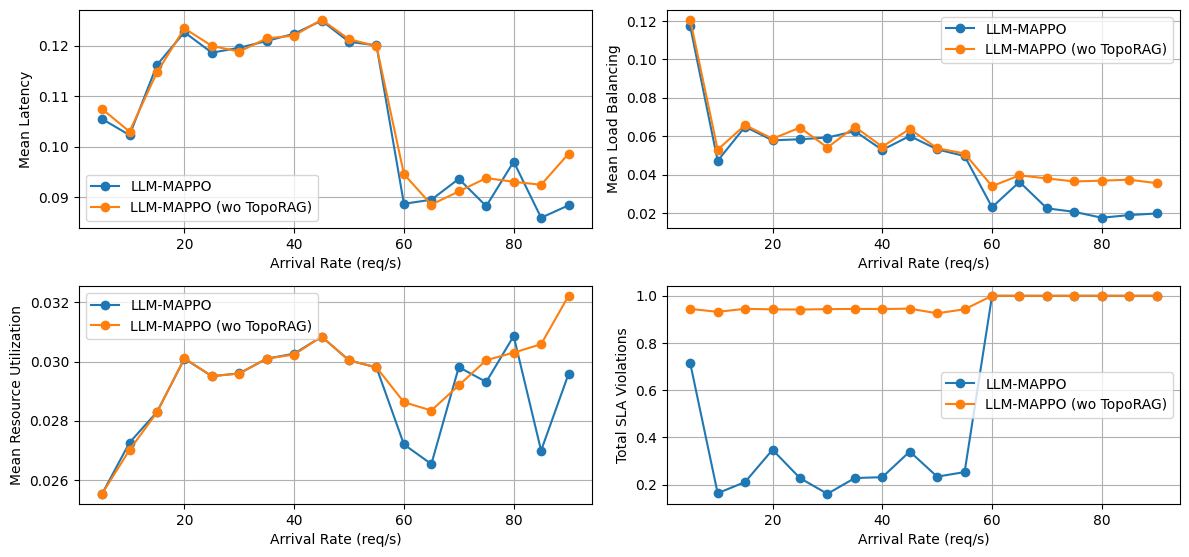

In [57]:
summaries = load_summary_files(directory="out", run_name="0729_085632")
metrics, slas, arrival_rates = extract_metrics(summaries)

summaries = load_summary_files(directory="out-notoporag", run_name="0729_085632")
metrics1, slas1, arrival_rates1 = extract_metrics(summaries)

plot_metrics([arrival_rates, arrival_rates1], [metrics, metrics1], [slas, slas1])

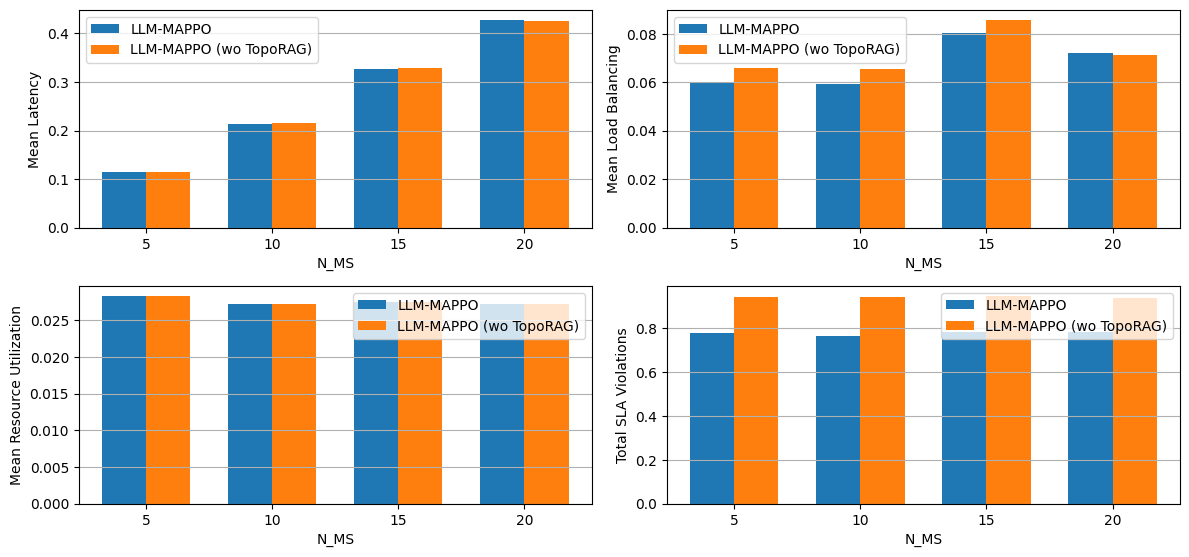

In [58]:
summaries = load_summary_files(directory="out-nms", run_name="0729_085632")
metrics, slas, nms = extract_metrics_nms(summaries)

summaries = load_summary_files(directory="out-nms-notoporag", run_name="0729_085632")
metrics1, slas1, nms1 = extract_metrics_nms(summaries)

plot_metrics_bar([nms, nms1], [metrics, metrics1], [slas, slas1])